# 17 · Is there anything to trade? (work package 8)

**Work package 8**, implementation plan section 12.7, step 8. Before any backtest, this notebook checks on
development data (2 July – 10 September) the links every strategy rests on:

- **Link 1, tail strategy:** do the tokens each rule picks get new buyers in the next 48 hours?
- **Link 2, tail strategy:** do new buyers move prices up?
- **Launch momentum:** how often do young tokens, picked by their order flow or at random, later reach 3×, 5× or
  20× at a price at which one could actually sell? And how soon after launch do prices peak?

Nothing here is tuned; the rules use the defaults of the plan ($K = 5$ for the tail, universe of 12.4).

In [1]:
import sys

sys.path.append("../scripts")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import plots
import prices as px
import strategy as st
import token_data as td

plots.style()
pd.set_option("display.float_format", "{:,.3f}".format)
OUT = td.PROJECT_DIR.parent.parent / "results" / "wp8"
OUT.mkdir(parents=True, exist_ok=True)

legs = td.load_legs()
signal_files = sorted(st.SIGNAL_DIR.glob("signal_*.parquet"))
print(f"{len(signal_files)} decision times with a signal")

280 decision times with a signal


## 1. Link 1: new buyers of the picked tokens

A **new buyer** of token $i$ after decision time $s$: an account whose first trade of $i$ ever is a buy in the
48 hours after $s$. Computed from each account's first trade of each token.

In [2]:
first = legs.sort_values("timestamp", kind="stable").drop_duplicates(["user", "token"], keep="first")
first_buys = first[first["side"] == "buy"][["token", "timestamp"]]

VERSIONS = ["surprise", "filtered_visible", "unexplained_flow", "predicted", "tail_popularity", "tail_flow", "random"]
rows = []
for path in signal_files:
    signal = pd.read_parquet(path)
    s = signal["decision"].iloc[0]
    window = first_buys[(first_buys["timestamp"] >= s) & (first_buys["timestamp"] < s + pd.Timedelta(hours=48))]
    new_buyers = window.groupby("token").size()
    for version in VERSIONS:
        picked = st.select(signal, version, k=5)
        for token in picked["token"]:
            rows.append({"decision": s, "version": version, "token": token, "new_buyers": int(new_buyers.get(token, 0))})
link1 = pd.DataFrame(rows)
link1.to_csv(OUT / "link1_new_buyers.csv", index=False)
per_version = link1.groupby("version")["new_buyers"].agg(["mean", "median", "count"]).reindex(VERSIONS)
per_version["share_with_any"] = link1.assign(any=link1["new_buyers"] > 0).groupby("version")["any"].mean()
per_version

,mean,median,count,share_with_any
version,,,,
surprise,12.605,8.000,1400,0.974
filtered_visible,35.596,23.000,1400,0.994
unexplained_flow,19.866,6.000,1400,0.846
predicted,19.044,11.000,1400,0.980
tail_popularity,47.840,23.000,1400,0.965
tail_flow,23.411,14.000,1400,0.983
random,16.075,10.000,1400,0.966


Paired by decision time: each version against tail popularity (the primary benchmark), mean new buyers per picked
token, with the share of decision times at which the version picked tokens with more new buyers.

In [3]:
per_decision = link1.groupby(["decision", "version"])["new_buyers"].mean().unstack("version")
paired = pd.DataFrame({
    v: {"mean difference": (per_decision[v] - per_decision["tail_popularity"]).mean(),
        "share of decisions ahead": (per_decision[v] > per_decision["tail_popularity"]).mean()}
    for v in VERSIONS if v != "tail_popularity"
}).T  # fmt: skip
paired

,mean difference,share of decisions ahead
surprise,-35.235,0.075
filtered_visible,-12.244,0.443
unexplained_flow,-27.974,0.121
predicted,-28.796,0.150
tail_flow,-24.429,0.132
random,-31.765,0.104


## 2. Link 2: do new buyers move prices?

For every token in the universe at a decision time: the log change of its ETH price from the first swap after
$s$ to the first swap after $s$ + 24 hours, in its most active pool, against the number of new buyers in those
24 hours. Pooled over all decision times.

In [4]:
prices = px.load_prices(td.PROJECT_FIRST_BLOCK, td.PROJECT_LAST_BLOCK)[["timestamp", "pool", "price_eth", "volume_eth", "side"]]
prices = prices[prices["volume_eth"] >= 0.01]
prices["pool"] = prices["pool"].astype("category")
by_pool = {pool: (part["timestamp"].dt.tz_localize(None).to_numpy(), part["price_eth"].to_numpy()) for pool, part in prices.groupby("pool", observed=True)}


def price_at(pool, t):
    """ETH price of the first swap of at least 0.01 ETH at or after t in the pool, or NaN."""
    if pool not in by_pool:
        return np.nan
    times, values = by_pool[pool]
    i = np.searchsorted(times, np.datetime64(t.tz_convert("UTC").tz_localize(None)))
    return values[i] if i < len(values) else np.nan


rows = []
for path in signal_files[::4]:  # one decision a day keeps the sample independent across days
    signal = st.universe(pd.read_parquet(path))
    s = signal["decision"].iloc[0] if len(signal) else None
    if s is None:
        continue
    window = first_buys[(first_buys["timestamp"] >= s) & (first_buys["timestamp"] < s + pd.Timedelta(hours=24))]
    new_buyers = window.groupby("token").size()
    for item in signal.itertuples():
        p0, p1 = price_at(item.pool, s), price_at(item.pool, s + pd.Timedelta(hours=24))
        rows.append({"decision": s, "token": item.token, "new_buyers": int(new_buyers.get(item.token, 0)),
                     "log_return": np.log(p1 / p0) if p0 > 0 and p1 > 0 else np.nan})  # fmt: skip
link2 = pd.DataFrame(rows).dropna()
link2.to_csv(OUT / "link2_price_moves.csv", index=False)
link2["buyers_group"] = pd.cut(link2["new_buyers"], [-1, 0, 2, 10, 50, np.inf], labels=["0", "1-2", "3-10", "11-50", "51+"])
link2.groupby("buyers_group", observed=True)["log_return"].agg(["count", "mean", "median"])

,count,mean,median
buyers_group,,,
0,603,-0.017,-0.007
1-2,1564,-0.026,-0.009
3-10,4499,-0.019,-0.009
11-50,2243,-0.000,-0.000
51+,144,0.067,0.093


## 3. Launch momentum: how often is there a sellable large gain?

For young tokens (15 minutes to 6 hours old) at each hourly decision, from the launch tables: entry at the
decision, at the price of the last buy swap before it (the backtest's entry rule), then the highest **sellable**
price within 72 hours. A token never traded again after the decision (a rug pull, a dead launch) is never
sellable; it is not skipped. A price counts as
sellable when a sell swap of at least 0.05 ETH reached it and another sell swap followed (someone still bought).
Compared for the tokens picked by order flow (most buyers in the last hour, at least 10 buyers since launch and a
buy share of at least 0.5, $K = 3$ per hour) and for random tokens of the same universe.

In [5]:
del prices, by_pool  # 8 GB machine: free the previous section's prices before loading them again
launch = pd.read_parquet(td.PROJECT_DIR / "launch_dev.parquet")
full = px.load_prices(td.PROJECT_FIRST_BLOCK, td.PROJECT_LAST_BLOCK)[["timestamp", "pool", "price_eth", "volume_eth", "side", "block"]]
full["pool"] = full["pool"].astype("category")
pool_arrays = {
    pool: {"time": part["timestamp"].dt.tz_localize(None).to_numpy(), "price": part["price_eth"].to_numpy(),
           "buy": (part["side"] == "buy").to_numpy(), "volume": part["volume_eth"].to_numpy()}
    for pool, part in full.groupby("pool", observed=True)
}  # fmt: skip


def best_sellable_multiple(pool, s, hours=72, min_eth=0.05):
    """Entry at s at the last buy before s; the highest sell price (swap >= min_eth, followed by another sell) within `hours`, as a multiple."""
    arrays = pool_arrays.get(pool)
    if arrays is None:
        return np.nan, np.nan
    t0 = np.datetime64(s.tz_convert("UTC").tz_localize(None))
    known = np.flatnonzero(arrays["time"] < t0)
    earlier_buys = known[arrays["buy"][known]]
    if not len(earlier_buys):
        return np.nan, np.nan
    i, entry_price = known[-1], arrays["price"][earlier_buys[-1]]
    end = t0 + np.timedelta64(hours, "h")
    sells = np.flatnonzero(~arrays["buy"] & (np.arange(len(arrays["buy"])) > i) & (arrays["time"] < end))
    if len(sells) < 2:
        return 0.0, np.nan
    candidates = sells[:-1][arrays["volume"][sells[:-1]] >= min_eth]
    if not len(candidates):
        return 0.0, np.nan
    best = candidates[np.argmax(arrays["price"][candidates])]
    hours_to_peak = (arrays["time"][best] - t0) / np.timedelta64(1, "h")
    return arrays["price"][best] / entry_price, hours_to_peak


rows, bought = [], {"launch_momentum": set(), "launch_random": set()}
for s, table in launch.groupby("decision"):
    for version in bought:
        picked = st.select_launch(table, version, k=3, min_buyers=10, min_buy_share=0.5, already=bought[version])
        for item in picked.itertuples():
            bought[version].add(item.token)
            multiple, to_peak = best_sellable_multiple(item.pool, s)
            rows.append({"decision": s, "version": version, "token": item.token, "multiple": multiple, "hours_to_peak": to_peak})
tail = pd.DataFrame(rows)
tail.to_csv(OUT / "launch_sellable_multiples.csv", index=False)
reach = pd.DataFrame({
    version: {"tokens": len(part), **{f"reach {m}x": (part["multiple"] >= m).mean() for m in (2, 3, 5, 10, 20)},
              "never sellable": (part["multiple"] == 0).mean(), "median hours to peak": part["hours_to_peak"].median()}
    for version, part in tail.groupby("version")
}).T  # fmt: skip
reach

,tokens,reach 2x,reach 3x,reach 5x,reach 10x,reach 20x,never sellable,median hours to peak
launch_momentum,"3,574.000",0.046,0.032,0.025,0.017,0.011,0.760,0.420
launch_random,"4,176.000",0.035,0.026,0.022,0.014,0.009,0.854,0.688


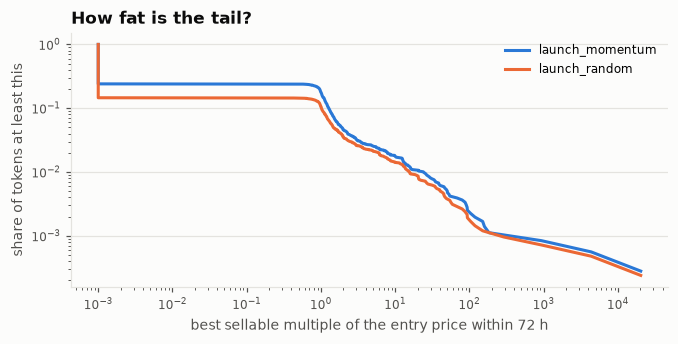

In [6]:
fig, ax = plt.subplots(figsize=(7, 3))
for slot, (version, part) in enumerate(tail.groupby("version")):
    values = np.sort(part["multiple"].dropna().clip(lower=1e-3).to_numpy())
    ax.plot(values, 1 - np.arange(len(values)) / len(values), color=plots.SERIES[slot], label=version)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("best sellable multiple of the entry price within 72 h")
ax.set_ylabel("share of tokens at least this")
ax.set_title("How fat is the tail?")
ax.legend()
plt.show()